In [17]:
# %% Imports
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

np.random.seed(42)
random.seed(42)
keras.utils.set_random_seed(42)
warnings.filterwarnings('ignore')

print("keras version:", keras.__version__)
print("Numpy version:", np.__version__)
print("Backend:", keras.backend.backend())

keras version: 3.15.1
Numpy version: 2.5.3
Backend: tensorflow


In [18]:
# %% STEP 1: Paths aur settings  (apne folder ke hisaab se badlo)
# Notebook "notebooks" folder me hai, isliye ".." se ek folder peeche jaake data lenge.
# Agar script project root se chala rahe ho to "data/train" likho.

TRAIN_DIR = "D:/D.L. Project/data/train"
VAL_DIR   = "D:/D.L. Project/data/val"
TEST_DIR  = "D:/D.L. Project/data/test"

IMG_SIZE = 64
MAX_CLASSES = 5               # sirf 5 classes 
TRAIN_PER_CLASS = 300
VAL_PER_CLASS = 100
TEST_PER_CLASS = 100

class_names = sorted(os.listdir(TRAIN_DIR))[:MAX_CLASSES]
print("Classes:", class_names)

Classes: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot']


In [19]:
# %% STEP 2: Load function (ek hi function teeno folders ke liye)
def load_split(split_dir, per_class):
    images, labels = [], []
    for label, name in enumerate(class_names):
        folder = os.path.join(split_dir, name)
        files = sorted(os.listdir(folder))[:per_class]
        for f in files:
            img = Image.open(os.path.join(folder, f)).convert("RGB")
            img = img.resize((IMG_SIZE, IMG_SIZE))
            images.append(np.array(img))
            labels.append(label)
    return np.array(images), np.array(labels)

x_train_small, y_train_small = load_split(TRAIN_DIR, TRAIN_PER_CLASS)
x_val_small, y_val_small = load_split(VAL_DIR, VAL_PER_CLASS)
x_test_small, y_test_small = load_split(TEST_DIR, TEST_PER_CLASS)

print("x_train shape:", x_train_small.shape)
print("x_val shape:", x_val_small.shape)
print("x_test shape:", x_test_small.shape)

x_train shape: (1500, 64, 64, 3)
x_val shape: (500, 64, 64, 3)
x_test shape: (500, 64, 64, 3)


First image shape: (64, 64, 3)
First image label: 0 -> Tomato___Bacterial_spot
Data type: uint8
Min pixel: 0  Max pixel: 255
Nan values: 0


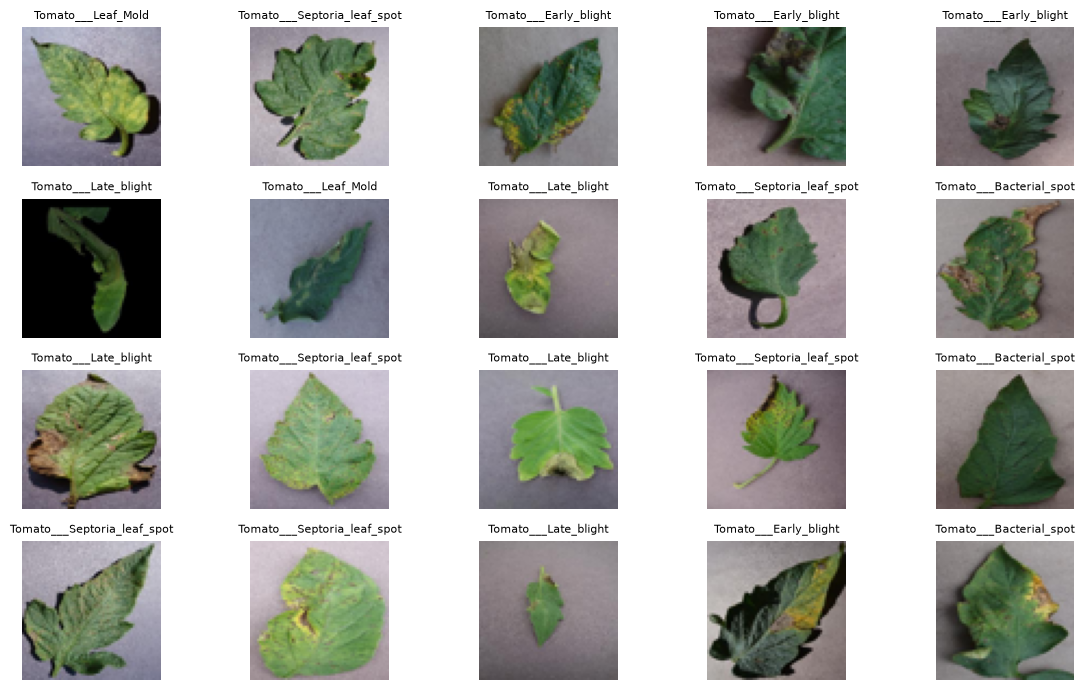

In [20]:

# %% STEP 3: Data check
print("First image shape:", x_train_small[0].shape)
print("First image label:", y_train_small[0], "->", class_names[y_train_small[0]])
print("Data type:", x_train_small.dtype)
print("Min pixel:", x_train_small.min(), " Max pixel:", x_train_small.max())
print("Nan values:", np.isnan(x_train_small).sum())

plt.figure(figsize=(12, 7))
idx = np.random.choice(len(x_train_small), 20, replace=False)
for n, i in enumerate(idx):
    plt.subplot(4, 5, n + 1)
    plt.imshow(x_train_small[i])
    plt.title(class_names[y_train_small[i]], fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

   Label                        Class  Count
0      0      Tomato___Bacterial_spot    300
1      1        Tomato___Early_blight    300
2      2         Tomato___Late_blight    300
3      3           Tomato___Leaf_Mold    300
4      4  Tomato___Septoria_leaf_spot    300


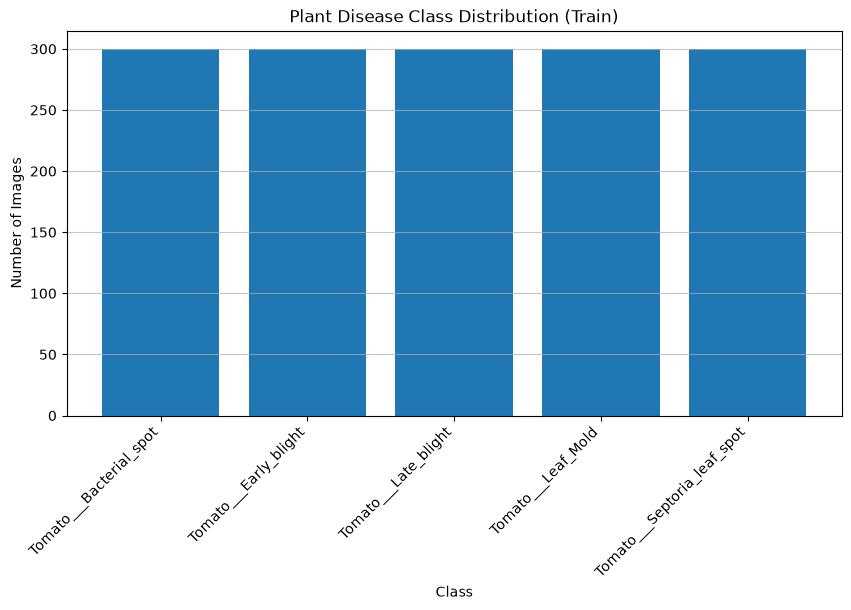

In [21]:
# %% STEP 4: Class distribution (train)
unique_labels, counts = np.unique(y_train_small, return_counts=True)
class_distribution = pd.DataFrame({
    "Label": unique_labels,
    "Class": [class_names[i] for i in unique_labels],
    "Count": counts
})
print(class_distribution)

plt.figure(figsize=(10, 5))
plt.bar(class_distribution["Class"], class_distribution["Count"])
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("Plant Disease Class Distribution (Train)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.7)
plt.show()

In [22]:
# %% STEP 5: Normalize
x_train_small = x_train_small.astype("float32") / 255.0
x_val_small = x_val_small.astype("float32") / 255.0
x_test_small = x_test_small.astype("float32") / 255.0
print("New min:", x_train_small.min(), " New max:", x_train_small.max())

New min: 0.0  New max: 1.0


In [23]:
# %% STEP 6: Flatten
x_train_flat = x_train_small.reshape(len(x_train_small), -1)
x_val_flat = x_val_small.reshape(len(x_val_small), -1)
x_test_flat = x_test_small.reshape(len(x_test_small), -1)


print("Original image shape:", x_train_small[0].shape)
print("Flattened sample shape:", x_val_flat[0].shape)
print("Test matrix shape:", x_test_flat.shape)

Original image shape: (64, 64, 3)
Flattened sample shape: (12288,)
Test matrix shape: (500, 12288)


Logistic regression trained!
First 20 actual   : [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
First 20 predicted: [0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 1 0 1]


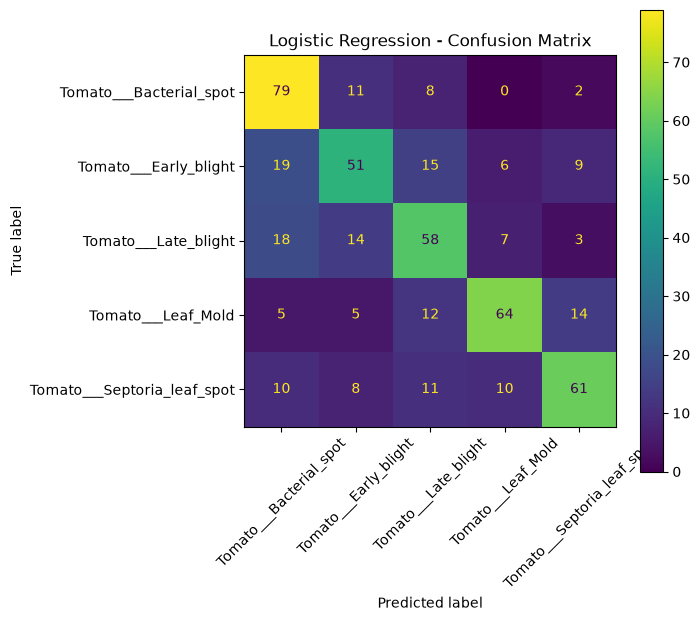

Logistic Regression Accuracy: 62.60%
                             precision    recall  f1-score   support

    Tomato___Bacterial_spot       0.60      0.79      0.68       100
      Tomato___Early_blight       0.57      0.51      0.54       100
       Tomato___Late_blight       0.56      0.58      0.57       100
         Tomato___Leaf_Mold       0.74      0.64      0.68       100
Tomato___Septoria_leaf_spot       0.69      0.61      0.65       100

                   accuracy                           0.63       500
                  macro avg       0.63      0.63      0.62       500
               weighted avg       0.63      0.63      0.62       500



In [24]:
# %% STEP 7: Logistic Regression
logistic_model = LogisticRegression(solver="lbfgs", max_iter=300, random_state=42)
logistic_model.fit(x_train_flat, y_train_small)
print("Logistic regression trained!")

y_pred_lr = logistic_model.predict(x_test_flat)
print("First 20 actual   :", y_test_small[:20])
print("First 20 predicted:", y_pred_lr[:20])

accuracy_lr = accuracy_score(y_test_small, y_pred_lr)
cm_lr = confusion_matrix(y_test_small, y_pred_lr)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=class_names)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, xticks_rotation=45, values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()
print(f"Logistic Regression Accuracy: {accuracy_lr * 100:.2f}%")
print(classification_report(y_test_small, y_pred_lr,
                            target_names=class_names, zero_division=0))

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │       786,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 786,821 (3.00 MB)

 Trainable params: 786,821 (3.00 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.3207 - loss: 1.5261 - val_accuracy: 0.4020 - val_loss: 1.4338
Epoch 2/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.4727 - loss: 1.3430 - val_accuracy: 0.4140 - val_loss: 1.4037
Epoch 3/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5193 - loss: 1.2588 - val_accuracy: 0.4420 - val_loss: 1.3503
Epoch 4/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5387 - loss: 1.2123 - val_accuracy: 0.4580 - val_loss: 1.3215
Epoch 5/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5607 - loss: 1.1734 - val_accuracy: 0.4720 - val_loss: 1.2916
Epoch 6/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5760 - loss: 1.1406 - val_accuracy: 0.4740 - val_loss: 1.2703
Epoch 7/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5780 - loss: 1.1188 - val_accuracy: 0.4960 - val_loss: 1.2578
Epoch 8/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5920 - loss: 1.0862 - val_accuracy: 0.5020 - val_l

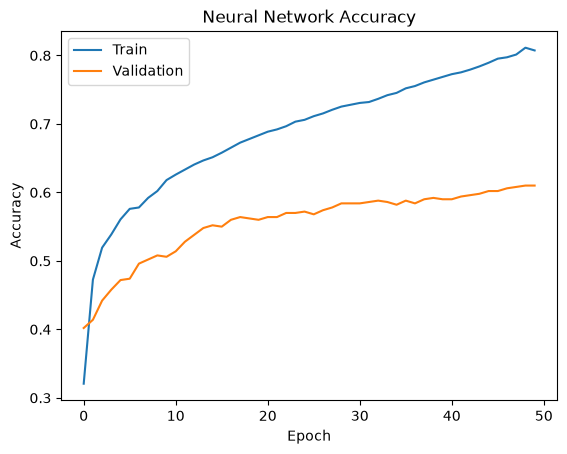

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6500 - loss: 0.8899 
Test Loss (NN): 0.8899
Test Accuracy (NN): 65.00%


In [26]:
# %% STEP 8: Neural Network
num_classes = len(class_names)
input_dim = x_train_flat.shape[1]

nn_model = keras.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(num_classes, activation="softmax")
])
nn_model.summary()

nn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = nn_model.fit(
    x_train_flat, y_train_small,
    validation_data=(x_val_flat, y_val_small),
    epochs=50,
    batch_size=32,
    verbose=1
)

plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Neural Network Accuracy")
plt.legend()
plt.show()

test_loss_nn, test_accuracy_nn = nn_model.evaluate(x_test_flat, y_test_small, verbose=1)
print(f"Test Loss (NN): {test_loss_nn:.4f}")
print(f"Test Accuracy (NN): {test_accuracy_nn * 100:.2f}%")

In [27]:


# %% STEP 9: Comparison
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Neural Network"],
    "Test Accuracy": [accuracy_lr, test_accuracy_nn]
})
comparison["Test Accuracy(%)"] = comparison["Test Accuracy"] * 100
print(comparison.round(2))

                 Model  Test Accuracy  Test Accuracy(%)
0  Logistic Regression           0.63              62.6
1       Neural Network           0.65              65.0


<!-- Here We Use-> CNN Model -->

In [28]:
cnn_model = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(num_classes, activation="softmax")
])
cnn_model.summary()

cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │       294,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 388,549 (1.48 MB)

 Trainable params: 388,549 (1.48 MB)

 Non-trainable params: 0 (0.00 B)

CNN training

Epoch 1/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.9987 - loss: 0.0060 - val_accuracy: 0.8240 - val_loss: 0.8322
Epoch 2/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 1.0000 - loss: 0.0044 - val_accuracy: 0.8180 - val_loss: 0.8586
Epoch 3/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.9987 - loss: 0.0051 - val_accuracy: 0.8180 - val_loss: 0.8712
Epoch 4/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.9993 - loss: 0.0048 - val_accuracy: 0.8180 - val_loss: 0.8772
Epoch 5/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 1.0000 - loss: 0.0030 - val_accuracy: 0.8160 - val_loss: 0.8676
Epoch 6/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 1.0000 - loss: 0.0022 - val_accuracy: 0.8140 - val_loss: 0.8662
Epoch 7/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 1.0000 - loss: 0.0026 - val_accuracy: 0.8200 - val_loss: 0.8762
Epoch 8/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.9993 - loss: 0.0039 - val_accuracy: 0.8200 - v

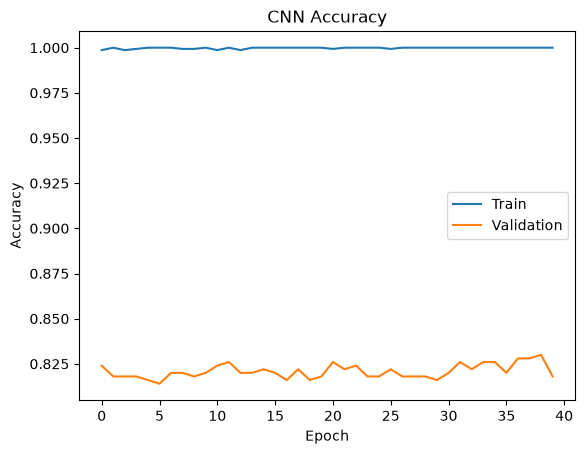

In [34]:

history_cnn = cnn_model.fit(
    x_train_small, y_train_small,
    validation_data=(x_val_small, y_val_small),
    epochs=40,
    batch_size=32,
    verbose=1
)

plt.plot(history_cnn.history["accuracy"], label="Train")
plt.plot(history_cnn.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()
plt.show()

CNN evaluation

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8620 - loss: 0.7820
Test Accuracy (CNN): 86.20%
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


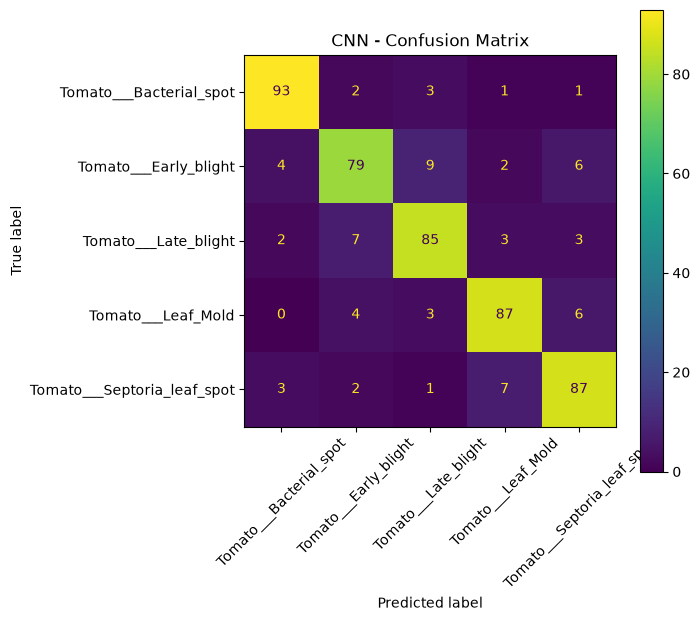

                             precision    recall  f1-score   support

    Tomato___Bacterial_spot       0.91      0.93      0.92       100
      Tomato___Early_blight       0.84      0.79      0.81       100
       Tomato___Late_blight       0.84      0.85      0.85       100
         Tomato___Leaf_Mold       0.87      0.87      0.87       100
Tomato___Septoria_leaf_spot       0.84      0.87      0.86       100

                   accuracy                           0.86       500
                  macro avg       0.86      0.86      0.86       500
               weighted avg       0.86      0.86      0.86       500



In [35]:
test_loss_cnn, test_accuracy_cnn = cnn_model.evaluate(
    x_test_small, y_test_small, verbose=1
)
print(f"Test Accuracy (CNN): {test_accuracy_cnn * 100:.2f}%")

y_pred_cnn = np.argmax(cnn_model.predict(x_test_small), axis=1)
cm_cnn = confusion_matrix(y_test_small, y_pred_cnn)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_cnn,
                              display_labels=class_names)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, xticks_rotation=45, values_format="d")
plt.title("CNN - Confusion Matrix")
plt.show()

print(classification_report(y_test_small, y_pred_cnn,
                            target_names=class_names, zero_division=0))

Final comparison (teeno models)

In [36]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Neural Network", "CNN"],
    "Test Accuracy": [accuracy_lr, test_accuracy_nn, test_accuracy_cnn]
})
comparison["Test Accuracy(%)"] = comparison["Test Accuracy"] * 100
print(comparison.round(2))

                 Model  Test Accuracy  Test Accuracy(%)
0  Logistic Regression           0.63              62.6
1       Neural Network           0.65              65.0
2                  CNN           0.86              86.2
